# Module 5 - Deploying ML Models

## Setup

### Configure libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Force numbers to display as decimals, not scientific notation
np.set_printoptions(suppress=True)

RANDOM_SEED = 1

### Load the dataset

In [2]:
df = pd.read_csv('../03_classification/churn_data.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Clean the data

In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,0
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.50,0
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,1
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,0
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,1


### Split the data

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=RANDOM_SEED)

print(df_full_train.shape)
print(df_test.shape)

(5634, 21)
(1409, 21)


### Define train and predict functions

In [5]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]

In [6]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [7]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

### Cross-validation

In [8]:
C = 1.0
n_splits = 5

In [9]:
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.churn.values
    y_val = df_val.churn.values

    dv, model = train(df_train, y_train, C=C)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

/home/red/ml-zoomcamp-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/red/ml-zoomcamp-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable

C=1.0 0.842 +- 0.007


In [10]:
scores

[0.8446829053857807,
 0.8451798602834062,
 0.8332289785269917,
 0.8347808882778027,
 0.8517225691067114]

### Compute AUC

In [11]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

y_test = df_test.churn.values
auc = roc_auc_score(y_test, y_pred)
auc

0.8583517501381259

## Overview

1. We have built, trained, and evaluated a model in a Jupyter Notebook

2. We save the trained model as a physical file so that it can be used later

3. We embed the model into an application/server, this is where it will actually be used in production

4. The Marketing team has an application that stores user data, so they send user features as a request to the churn service, and the churn service outputs a prediction back to the marketing service

5. The Marketing team should now be able to send promos to users who are at risk of churn

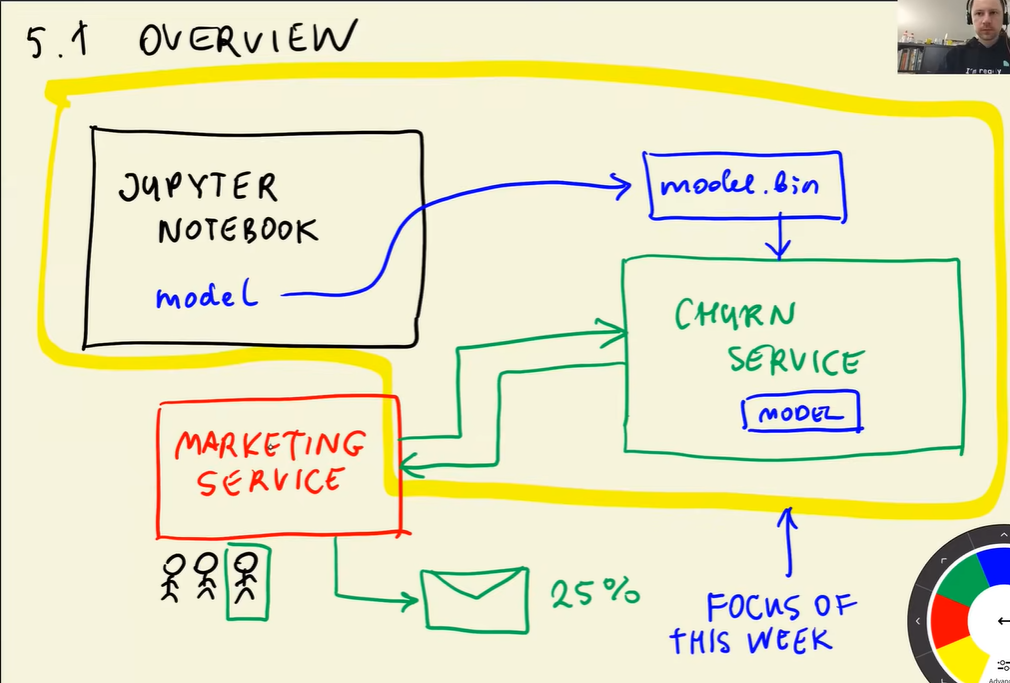

The following diagram uses some older tools. 

The updated tools we will use are:

- **FastAPI**, instead of Flask
- **uv**, instead of Pipenv
- **Fly.io** instead of AWS EBS
- We still use **Docker**

While we are using different set of tools, it is important to remember that regardless of tools, the fundamentals of this architecture are still the same:

- Model is served within an API (web service)
- We need an environment for Python dependencies
- We need an environment for system-wide dependencies
- We need a platform to deploy our API

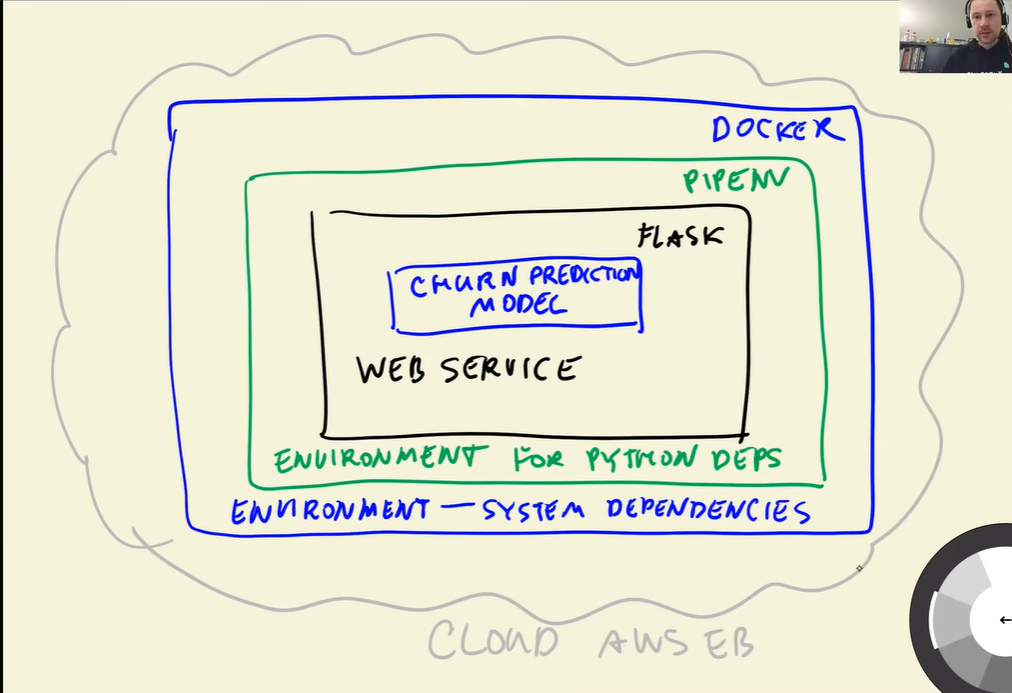

## Saving and Loading the Model

**Topics:**

- Saving the model to pickle
- Loading the model from pickle
- Turning our notebook into Python script

### Save the model

In [12]:
import pickle

In [13]:
output_file = f'model_C={C}.bin'
output_file

'model_C=1.0.bin'

In [14]:
with open(output_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)

### Load the model

In [15]:
with open(output_file, 'rb') as f_in:
    dv, model = pickle.load(f_in)

In [16]:
dv

DictVectorizer(sparse=False)

In [17]:
model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

### Making a prediction

In [18]:
customer = {
    'gender': 'female',
    'seniorcitizen': 0,
    'partner': 'yes',
    'dependents': 'no',
    'phoneservice': 'no',
    'multiplelines': 'no_phone_service',
    'internetservice': 'dsl',
    'onlinesecurity': 'no',
    'onlinebackup': 'yes',
    'deviceprotection': 'no',
    'techsupport': 'no',
    'streamingtv': 'no',
    'streamingmovies': 'no',
    'contract': 'month-to-month',
    'paperlessbilling': 'yes',
    'paymentmethod': 'electronic_check',
    'tenure': 1,
    'monthlycharges': 29.85,
    'totalcharges': 29.85
}


In [19]:
X = dv.transform([customer])
X

array([[ 1.  ,  0.  ,  0.  ,  1.  ,  0.  ,  1.  ,  0.  ,  0.  ,  1.  ,
         0.  ,  1.  ,  0.  ,  0.  , 29.85,  0.  ,  1.  ,  0.  ,  0.  ,
         0.  ,  1.  ,  1.  ,  0.  ,  0.  ,  0.  ,  1.  ,  0.  ,  1.  ,
         0.  ,  0.  ,  1.  ,  0.  ,  1.  ,  0.  ,  0.  ,  1.  ,  0.  ,
         0.  ,  1.  ,  0.  ,  0.  ,  1.  ,  0.  ,  0.  ,  1.  , 29.85]])

In [20]:
model.predict_proba(X)[0, 1]

np.float64(0.6273177838726128)

### Turning the notebook into a Python script

See `train.py` and `predict.py`

## Web Services - Intro to Flask

### Concept

A **web service** is a program that listens for requests over the network and sends back responses. It follows the client-server model:

- **Client (the user):** sends a request to the service. Here the request is `q=web+service`, a query parameter, like a search typed into a search engine.
- **Web service (the server):** receives the request, processes it, and sends a response back.
- **Response (the green box):** the data returned to the client, such as a web page with search results.

**Flow:** client → request → web service → response → client

For ML deployment, the web service wraps our trained model. The client sends input data (for example, customer features), and the service returns the model's prediction.


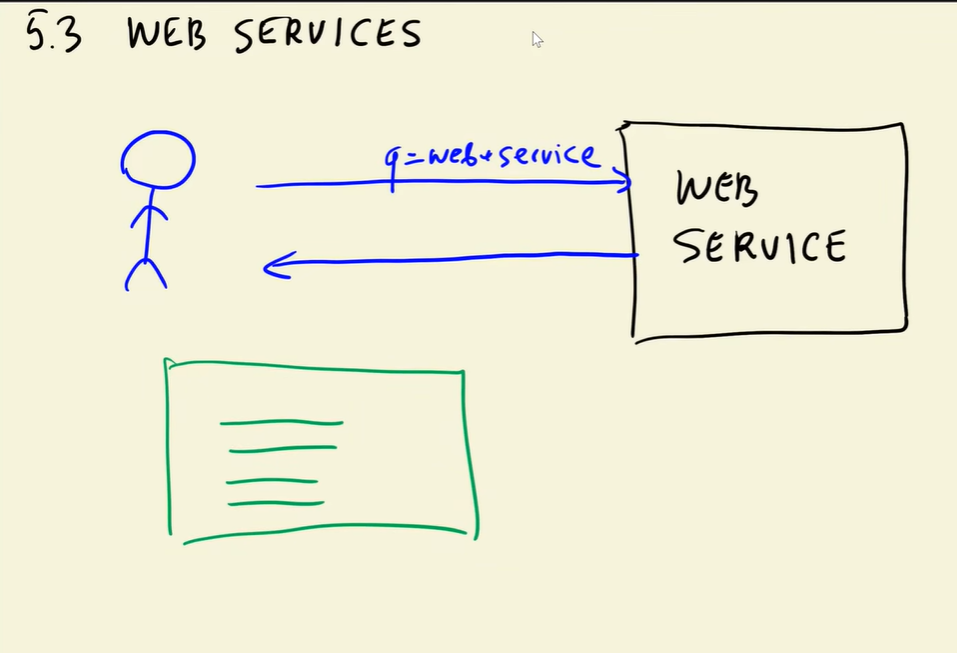

### Create a simple web service: ping-pong

See `ping.py`

## Serving the Churn Model with Flask

* Wrapping the predict script into a Flask app
* Querying it with `requests` 
* Preparing for production: gunicorn

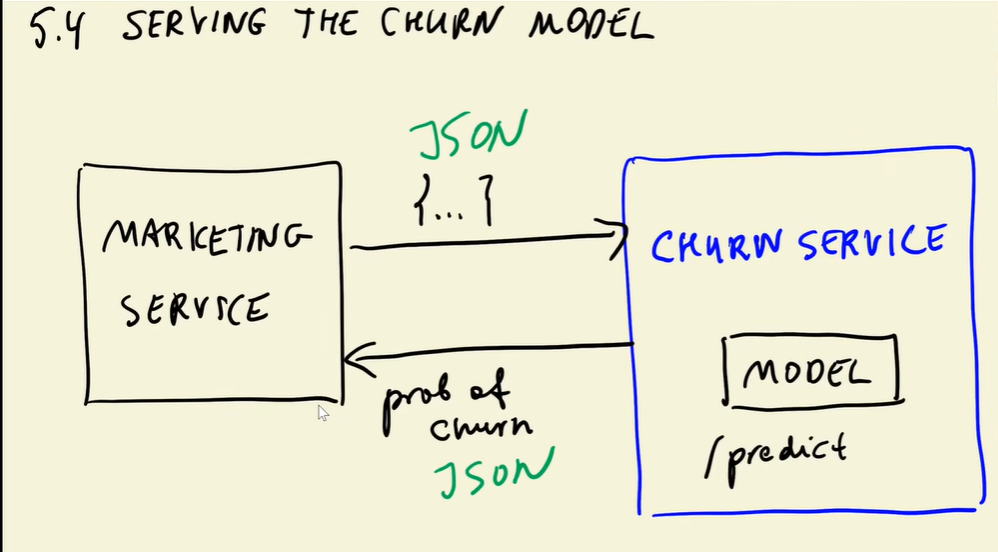

See `predict.py` to learn about how to package the trained model into a Flask API endpoint

### Sending a POST request to the model API

In [21]:
url = 'http://localhost:9696/predict'

customer = {
    "gender": "female",
    "seniorcitizen": 0,
    "partner": "yes",
    "dependents": "no",
    "phoneservice": "no",
    "multiplelines": "no_phone_service",
    "internetservice": "dsl",
    "onlinesecurity": "no",
    "onlinebackup": "yes",
    "deviceprotection": "no",
    "techsupport": "no",
    "streamingtv": "no",
    "streamingmovies": "no",
    "contract": "month-to-month",
    "paperlessbilling": "yes",
    "paymentmethod": "electronic_check",
    "tenure": 1,
    "monthlycharges": 29.85,
    "totalcharges": 29.85
}

In [27]:
import requests

response = requests.post(url, json=customer).json()
response

{'churn': True, 'churn_probability': 0.6273177838726128}

### Using a production WSGI server

Running `app.run()` starts Flask's built-in development server. It's fine for testing, but Flask warns against using it in production because it isn't built for load or stability.

A **WSGI server** sits between the client and the Flask app. It handles many requests at once and is more stable and secure.

| Server | Platform |
|---|---|
| **gunicorn** | Linux / macOS |
| **waitress** | Windows (also works on Linux / macOS) |

We use **gunicorn** because it runs on Linux, including in Docker.

**Install:**

```bash
uv add gunicorn
```

**Run:**

```bash
uv run gunicorn --bind 0.0.0.0:9696 predict:app
```

- `--bind 0.0.0.0:9696`: listen on port 9696 and accept outside connections
- `predict:app`: use the `app` variable in `predict.py`

**On Windows, use waitress instead:**

```bash
uv add waitress
uv run waitress-serve --listen=0.0.0.0:9696 predict:app
```

The client code (`requests.post(url, json=customer)`) stays the same. It doesn't matter which server is running behind the URL.


## Python Virtual Environments

What happens when you run `pip install scikit-learn`:

1. **Find `pip`:** the shell looks through `$PATH` and runs the first `pip` it finds, here `~/anaconda3/bin/pip`. The `python` that runs is the one in the same folder.
2. **Download:** `pip` fetches the package as a `.wheel` file (a pre-built package) from **pypi.org**.
3. **Install:** the package is installed into that same Anaconda Python.

**No version given means the latest version.** `pip install scikit-learn` installs whatever is newest on PyPI today.

**The problem:** everything installs into one shared (global) environment.
- Different projects may need different versions of the same library.
- Installing or upgrading for one project can break another.
- A model trained with one scikit-learn version can behave differently, or fail to load, under another.

**The fix is a virtual environment per project**, with versions pinned. With uv:

```bash
uv add scikit-learn   # installs into the project's own .venv and records the version
```


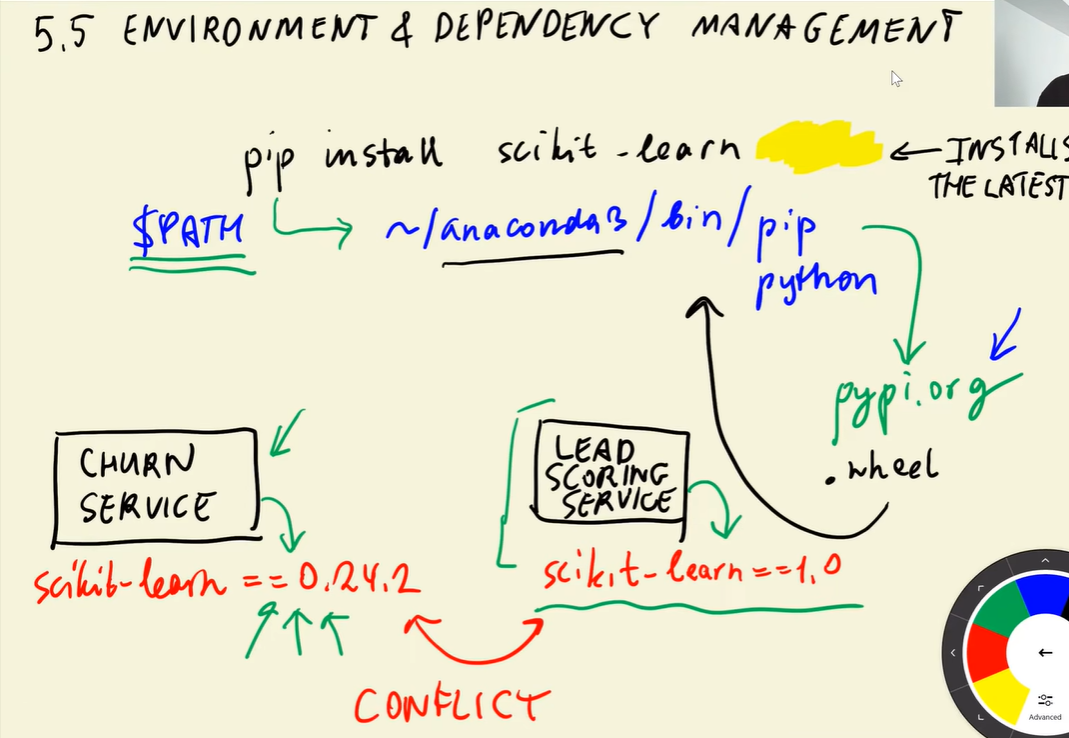

A **virtual environment** (venv) is an isolated folder with its own Python and its own installed packages. Each project gets its own, so projects don't affect each other.

**Example:** one laptop runs two services.

| Service | Environment | Python used |
|---|---|---|
| Churn service | `~/venv/churn` | `~/venv/churn/bin/python` |
| Lead scoring service | `~/venv/lead` | `~/venv/lead/bin/python` |

- `pip install scikit-learn` inside the churn venv installs only into `~/venv/churn`.
- The lead scoring service can use a different scikit-learn version, or none at all.
- **No conflicts:** upgrading or breaking a package in one environment can't affect the other.

**With uv**, the venv is created and used automatically per project:

```bash
uv add scikit-learn   # creates .venv if needed, installs into it
uv run python predict.py   # runs with that project's Python
```


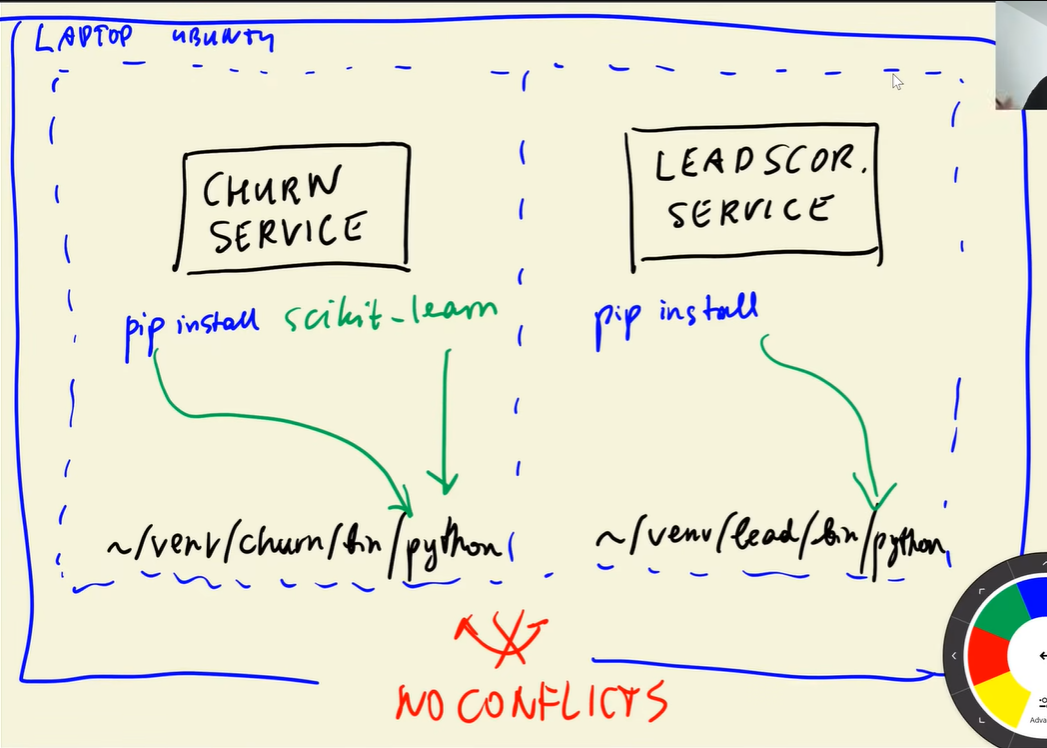

**Essential `uv` commands**

| Command | What it does |
|---|---|
| `uv init` | Create a new project (`pyproject.toml`, etc.) |
| `uv add flask` | Install a package into `.venv` and record it in `pyproject.toml` and `uv.lock` |
| `uv add flask==3.0.0` | Same, but pin a specific version |
| `uv add --dev pytest` | Add a dev-only dependency (not needed in production) |
| `uv remove flask` | Uninstall a package and remove it from `pyproject.toml` |
| `uv sync` | Create or update `.venv` to match `pyproject.toml` and `uv.lock` (use after cloning a project) |
| `uv lock` | Update `uv.lock` with exact versions without installing |
| `uv run python app.py` | Run a script using the project's `.venv` |
| `uv run gunicorn ...` | Run any installed tool inside the project's environment |
| `uv venv` | Create a `.venv` manually |
| `uv pip install flask` | pip-compatible install into `.venv` (doesn't update `pyproject.toml`) |
| `uv pip list` | List installed packages |
| `uv tree` | Show the dependency tree |
| `uv python install 3.12` | Download and install a specific Python version |

**Files uv manages:**
- `pyproject.toml`: the packages you asked for
- `uv.lock`: the exact versions of everything installed, for reproducibility (commit this)
- `.venv/`: the actual environment (don't commit this)

**pipenv equivalents:**

| pipenv | uv |
|---|---|
| `pipenv install flask` | `uv add flask` |
| `pipenv install` | `uv sync` |
| `pipenv run python app.py` | `uv run python app.py` |
| `Pipfile` / `Pipfile.lock` | `pyproject.toml` / `uv.lock` |


## Docker

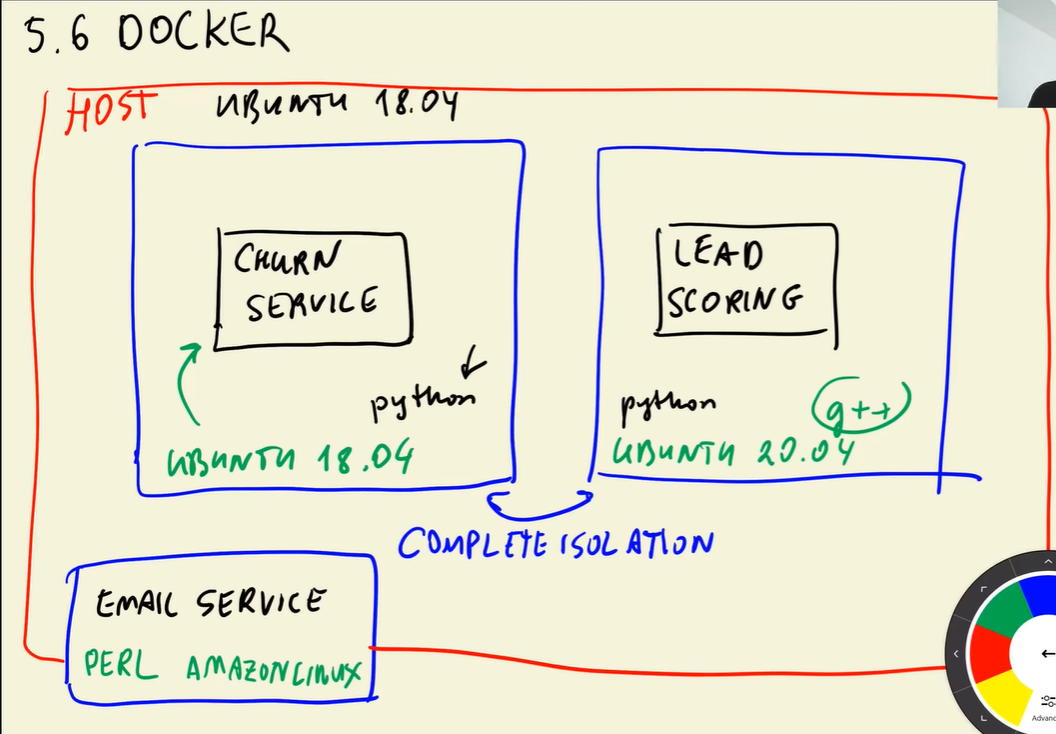

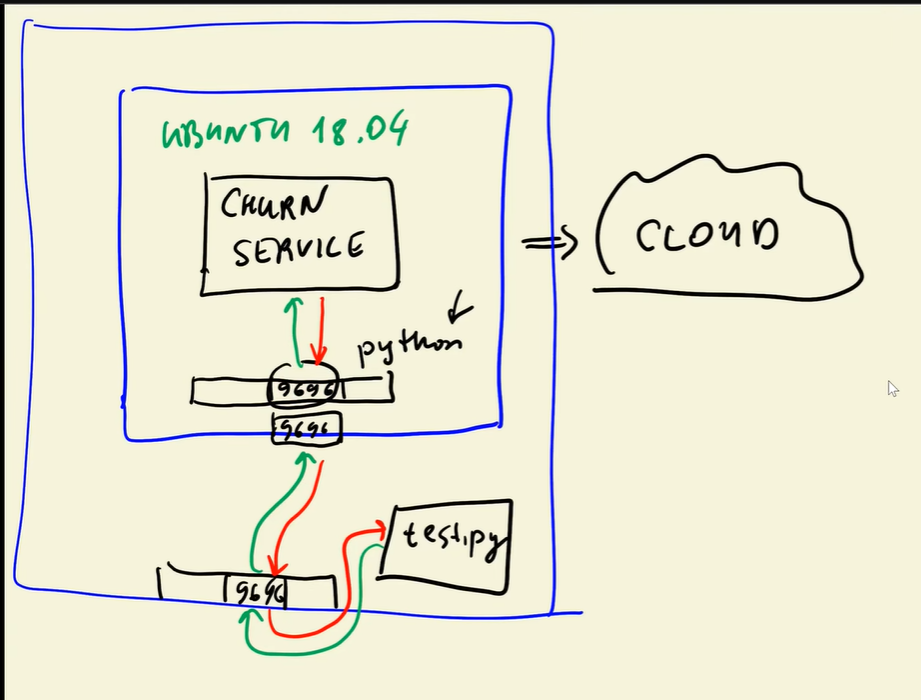

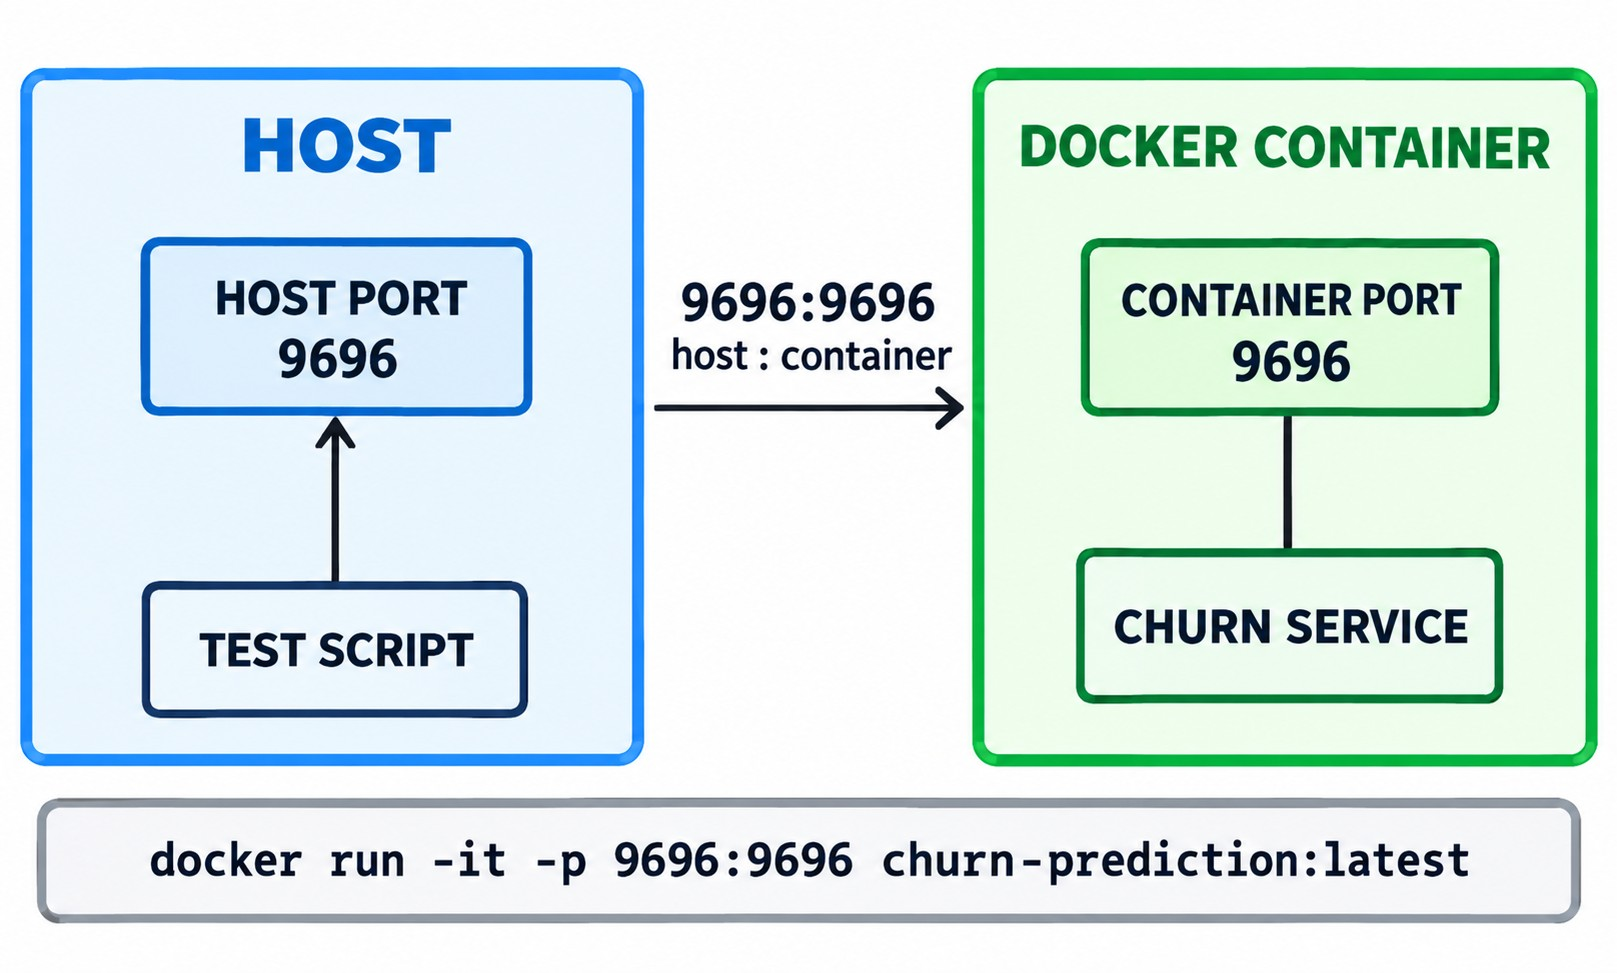